In [53]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
import plotly.express as px 


In [54]:
# Importing the cleaned dataset
artist_data= pd.read_csv("artist_streams_cleaned.csv")
artist_data.head()

,Artist Name,Sex,Country of Origin,Primary Language,Primary Genre,Artist Type,Debut Year,Total Streams,Lead Streams,Feature Streams,Solo Streams,Collaborative Streams,Update Date,Year
0,Drake,Male,Canada,English,Hip-Hop,Solo,2006.0,137492.1,94851.1,42640.9,53323.9,84168.2,2026-07-01 00:00:00,2026.0
1,Taylor Swift,Female,United States,English,Pop,Solo,2006.0,127861.0,126177.3,1683.8,113421.5,14439.5,2026-07-01 00:00:00,2026.0
2,Bad Bunny,Male,United States,Spanish,Reggaeton,Solo,2013.0,125899.8,82189.3,43710.5,48887.0,77012.8,2026-07-01 00:00:00,2026.0
3,The Weeknd,Male,Canada,English,R&B,Solo,2009.0,95703.2,77189.4,18513.8,51020.0,44683.2,2026-07-01 00:00:00,2026.0
4,Justin Bieber,Male,Canada,English,Pop,Solo,2009.0,78104.4,48316.2,29788.2,29638.3,48466.1,2026-07-01 00:00:00,2026.0


In [55]:
# Exploring career Length and streaming data
artist_data[['Artist Name','Debut Year','Year','Total Streams']]


,Artist Name,Debut Year,Year,Total Streams
0,Drake,2006.0,2026.0,137492.1
1,Taylor Swift,2006.0,2026.0,127861.0
2,Bad Bunny,2013.0,2026.0,125899.8
3,The Weeknd,2009.0,2026.0,95703.2
4,Justin Bieber,2009.0,2026.0,78104.4
...,...,...,...,...
495,The Cure,1979.0,2026.0,7034.1
496,The Marías,2017.0,2026.0,7029.1
497,Limp Bizkit,1997.0,2026.0,7018.9
498,Korn,1994.0,2026.0,6976.4


In [56]:
# Calculating the career Length of each artist

artist_data['Career Length']= artist_data['Year'] - artist_data['Debut Year']

artist_data[['Artist Name','Debut Year','Year','Career Length','Total Streams']].head()


,Artist Name,Debut Year,Year,Career Length,Total Streams
0,Drake,2006.0,2026.0,20.0,137492.1
1,Taylor Swift,2006.0,2026.0,20.0,127861.0
2,Bad Bunny,2013.0,2026.0,13.0,125899.8
3,The Weeknd,2009.0,2026.0,17.0,95703.2
4,Justin Bieber,2009.0,2026.0,17.0,78104.4


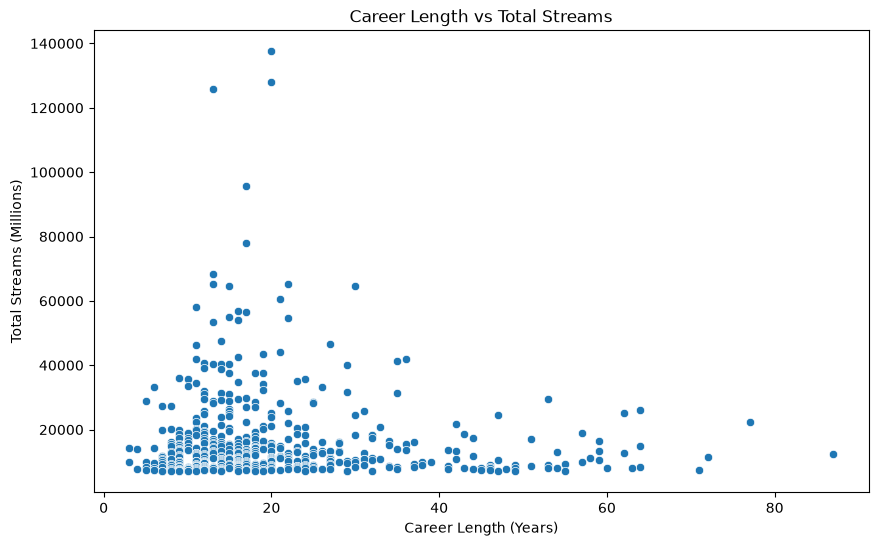

In [57]:
# Visualizing the relationship between career length and total streams

plt.figure(figsize=(10,6))

sns.scatterplot(data=artist_data, x='Career Length', y='Total Streams')

plt.title('Career Length vs Total Streams')
plt.xlabel('Career Length (Years)')
plt.ylabel('Total Streams (Millions)')

plt.show()

In [58]:
# Calculating the correlation between career Length and total streams

artist_data[['Career Length','Total Streams']].corr()

,Career Length,Total Streams
Career Length,1.000000,-0.068119
Total Streams,-0.068119,1.000000


The scatter plot shows no clear linear relationship between career length and total streams. The Pearson correlation coefficient (-0.0681) indicates a very weak negative correlation.

Artists with longer careers do not necessarily have more streams. In fact, some of the most-streamed artists have relatively shorter careers, suggesting that career length alone is not a strong indicator of streaming success.

In [59]:
#Calculating the percentage of streams from collaborations 

artist_data['Collaboration Percentage']= (artist_data['Collaborative Streams'] / artist_data['Total Streams']) *100

artist_data[['Artist Name','Collaboration Percentage']].head()


,Artist Name,Collaboration Percentage
0,Drake,61.216754
1,Taylor Swift,11.293123
2,Bad Bunny,61.169914
3,The Weeknd,46.689348
4,Justin Bieber,62.052970


In [60]:
#Identifying the top 5 artist with the highest collaboration percentage

top_5_collaborations= artist_data.sort_values( by='Collaboration Percentage', ascending=False).head(5)

top_5_collaborations[['Artist Name','Collaboration Percentage']]

,Artist Name,Collaboration Percentage
447,Kumaar,100.0
372,DJ Luian,100.0
89,Disney,100.0
246,Amitabh Bhattacharya,100.0
277,Irshad Kamil,100.0


In [61]:
#Checking the streaming values of the top 5 artists

top_5_collaborations[['Artist Name','Total Streams','Solo Streams','Collaborative Streams','Collaboration Percentage']]

,Artist Name,Total Streams,Solo Streams,Collaborative Streams,Collaboration Percentage
447,Kumaar,7689.5,0.0,7689.5,100.0
372,DJ Luian,8801.6,0.0,8801.6,100.0
89,Disney,22236.1,0.0,22236.1,100.0
246,Amitabh Bhattacharya,12136.7,0.0,12136.7,100.0
277,Irshad Kamil,11014.9,0.0,11014.9,100.0


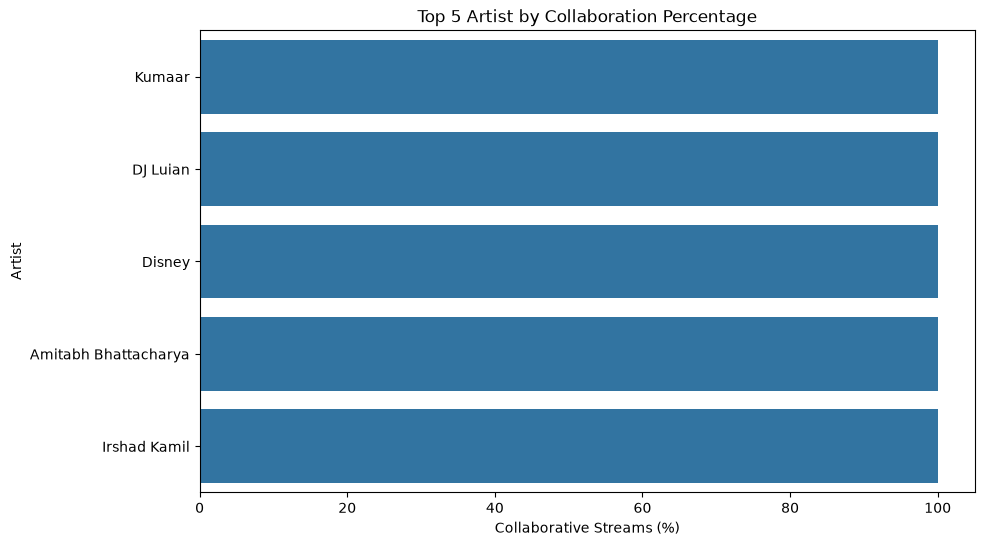

In [62]:
#Visualizing the top 5 artist by collaboration percentage

plt.figure(figsize=(10,6))

sns.barplot(data=top_5_collaborations, x='Collaboration Percentage',y='Artist Name')

plt.title('Top 5 Artist by Collaboration Percentage')
plt.xlabel('Collaborative Streams (%)')
plt.ylabel('Artist')

plt.show()

In [63]:
# Counting artists with 100% collaborative streams

(artist_data['Collaboration Percentage'] == 100).sum()

np.int64(7)


The analysis identified seven artists with 100% of their total streams coming from collaborations, as confirmed by counting the artists with a collaboration percentage equal to 100%.

The visualization presents five of these artists: Kumaar, DJ Luian, Disney, Amitabh Bhattacharya, and Irshad Kamil. All five have zero solo streams, meaning their entire streaming activity is classified as collaborative.

Since seven artists share the maximum percentage, the top five represent a selection of artists with equally high collaboration percentages.

In [64]:
#Calculating average total streams by music genre

genre_streams= artist_data.groupby('Primary Genre')['Total Streams'].mean()

genre_streams.sort_values(ascending=False)

Primary Genre
Spoken Word         24607.000000
Reggaeton           20671.048837
Pop                 19643.154902
Hip-Hop             18487.461739
R&B                 18409.625806
EDM                 16686.222727
Reggae              16598.000000
Alternative         16469.700000
K-Pop               14303.518182
Filmi               13759.809091
Soundtrack          13730.433333
Bachata             13550.466667
Rock                13534.773333
Regional Mexican    13475.473684
Country             13029.900000
Latin               12598.733333
Sertanjeo           11644.266667
Afrobeats           10719.800000
Folk                 9841.700000
Metal                9199.862500
Soul                 8348.266667
Children's Music     8316.500000
Nu Metal             7018.900000
Name: Total Streams, dtype: float64

In [65]:
#Comparing average streams and number of artist by genre

genre_analysis= artist_data.groupby('Primary Genre')['Total Streams'].agg(['mean','count'])

genre_analysis.sort_values(by='mean',ascending=False)


,mean,count
Primary Genre,,
Spoken Word,24607.000000,1
Reggaeton,20671.048837,43
Pop,19643.154902,102
Hip-Hop,18487.461739,115
R&B,18409.625806,31
EDM,16686.222727,22
Reggae,16598.000000,2
Alternative,16469.700000,9
K-Pop,14303.518182,11


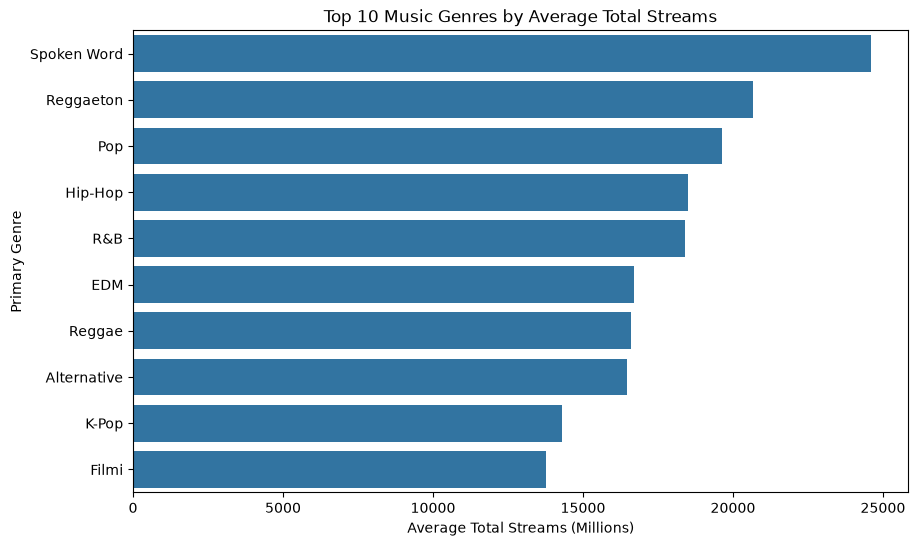

In [66]:
#Visualizing the top 10 genres by average total streams 

top_10_genres= genre_analysis.sort_values(by='mean', ascending=False).head(10)

plt.figure(figsize=(10,6))

sns.barplot(data=top_10_genres, x='mean', y=top_10_genres.index)

plt.title('Top 10 Music Genres by Average Total Streams')
plt.xlabel('Average Total Streams (Millions)')
plt.ylabel('Primary Genre')

plt.show()

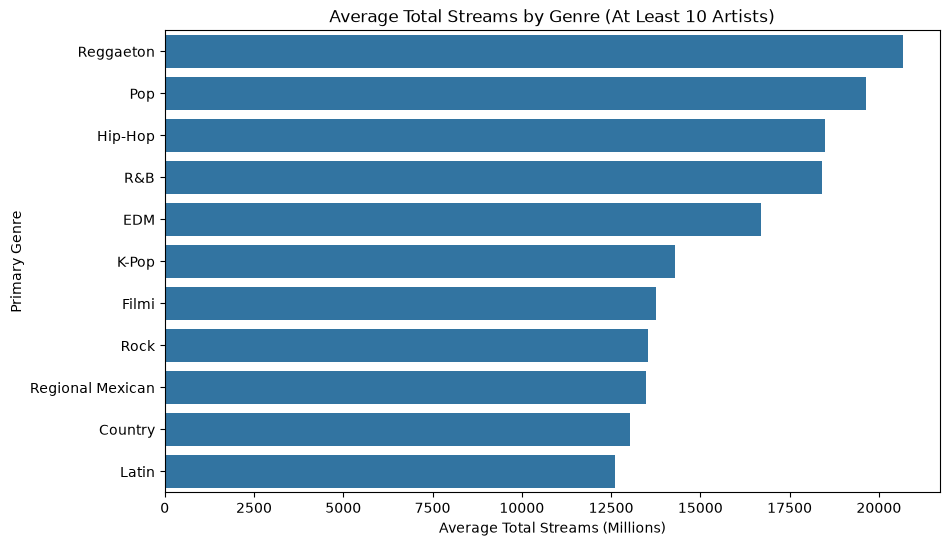

In [67]:
# Comparing average streams for genres with at least 10 artists

genres_10= genre_analysis[genre_analysis['count'] >= 10]

genres_10= genres_10.sort_values(by='mean', ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(data=genres_10, x='mean', y=genres_10.index)

plt.title('Average Total Streams by Genre (At Least 10 Artists)')
plt.xlabel('Average Total Streams (Millions)')
plt.ylabel('Primary Genre')

plt.show()

**Conclusion:**

The analysis reveals differences in average total streams across music genres. Initially, Spoken Word had the highest average (24,607 million streams), but this result was based on only one artist, limiting its representativeness.

When considering only genres with at least 10 artists, Reggaeton had the highest average (20,671 million), followed by Pop (19,643 million) and Hip-Hop (18,487 million).

These findings suggest that music genre is associated with streaming success, although the number of artists represented in each genre should be considered when interpreting the results.

In [68]:
#Comparing streaming performance between solo artists and groups

artist_type_analysis= artist_data.groupby('Artist Type')['Total Streams'].agg(['mean','median','count'])

artist_type_analysis

,mean,median,count
Artist Type,,,
Group,13290.162992,10607.0,127
Solo,18018.752011,12700.7,373


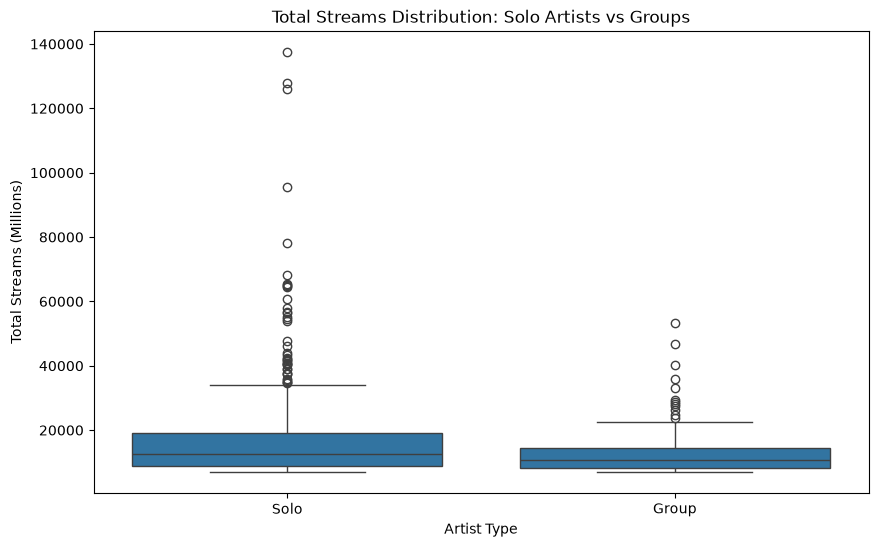

In [69]:
# Comparing the distribution of total streams between solo artists and groups

plt.figure(figsize=(10, 6))

sns.boxplot(data=artist_data, x='Artist Type', y='Total Streams')

plt.title('Total Streams Distribution: Solo Artists vs Groups')
plt.xlabel('Artist Type')
plt.ylabel('Total Streams (Millions)')

plt.show()

**Conclusion:**

Solo artists have higher average total streams (18,018.75 million) than groups (13,290.16 million). The median is also higher for solo artists (12,700.7 million compared to 10,607 million).

The boxplot shows that solo artists have more extreme streaming values, suggesting that a few highly successful artists influence the overall average.

These results indicate that solo artists tend to have higher streaming numbers within this dataset, although artist type alone does not necessarily determine streaming success.

In [70]:
#Comparing streaming performance by primary Language

language_analysis= artist_data.groupby('Primary Language')['Total Streams'].agg(['mean','median','count'])

language_analysis.sort_values(by='mean', ascending=False)

,mean,median,count
Primary Language,,,
English,17809.565588,12769.65,340
Spanish,15994.205714,11566.20,105
Tamil,15069.100000,15069.10,2
Hindi,14313.918182,10165.00,11
Korean,14303.518182,8531.30,11
German,11600.171429,8906.90,7
Portuguese,10962.600000,10122.50,15
French,10392.475000,9949.50,4
Italian,8858.800000,9437.30,3


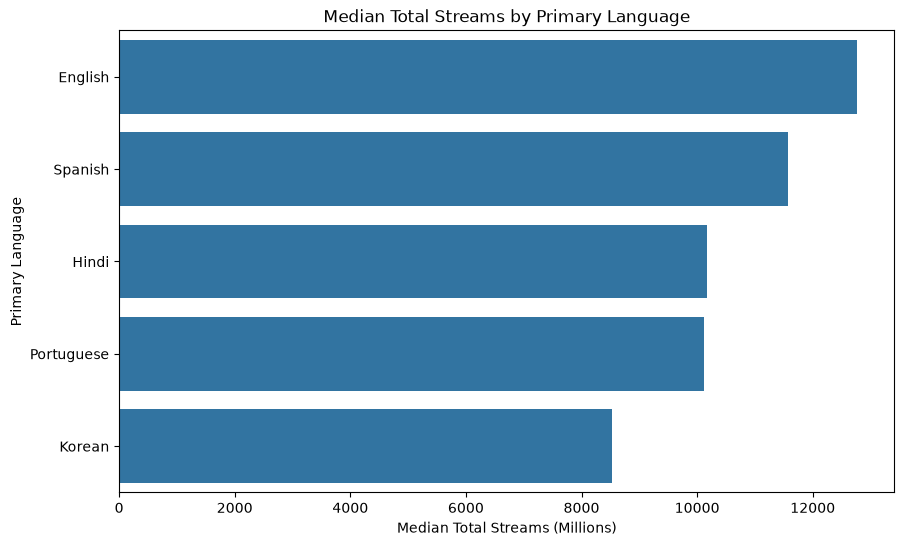

In [71]:
# Comparing median streams for languages with at least 10 artists

languages_10= language_analysis[language_analysis['count'] >= 10]

languages_10= languages_10.sort_values(by='median', ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(data=languages_10, x='median', y=languages_10.index)

plt.title('Median Total Streams by Primary Language')
plt.xlabel('Median Total Streams (Millions)')
plt.ylabel('Primary Language')

plt.show()

**Conclusion:**

The analysis shows differences in streaming performance across primary languages. English has the highest average total streams (17,809.57 million), followed by Spanish (15,994.21 million).

When comparing languages with at least 10 artists, English also has the highest median (12,769.65 million), followed by Spanish (11,566.20 million). Korean has the lowest median among the selected languages (8,531.30 million).

These results suggest an association between primary language and streaming performance. However, the unequal number of artists across languages and other factors may influence these differences.